In [63]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns


In [64]:
import os
import glob
import pandas as pd
import numpy as np

# --- 1. Load Data ---
strategies = ["strategy_one", "strategy_two", "strategy_three", "strategy_four"]
dfs = []

for strategy in strategies:
    results_path = f"{strategy}_repeats/{strategy}_results/"
    csv_files = glob.glob(os.path.join(results_path, "results_*.csv"))
    
    for f in csv_files:
        df = pd.read_csv(f)
        # Ensure the 'strategy' column exists and is correctly labeled
        df['strategy'] = strategy
        
        # Handle Strategy 4 categorical context
        if strategy == "strategy_four" and 'user_preference_type' in df.columns:
            # Map 'Minimize Infection' to 0 and 'Minimize NPI' to 1
            df['user_preference_type_numeric'] = df['user_preference_type'].map({
                'Minimize Infection': 0,
                'Minimize NPI': 1
            })
        
        dfs.append(df)

if dfs:
    full_results_df = pd.concat(dfs, ignore_index=True)
    print(f"Loaded {len(full_results_df)} records across {len(dfs)} CSV files from {len(strategies)} strategies.")
    print(full_results_df.groupby('strategy').size())
else:
    print("No CSV files found.")

Loaded 12950 records across 16 CSV files from 4 strategies.
strategy
strategy_four     2880
strategy_one      1439
strategy_three    4316
strategy_two      4315
dtype: int64


In [65]:
def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    strategy_lower = str(strategy_name).lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    return None

def format_strategy_name(strategy_name):
    """Format strategy name to use words instead of digits."""
    num_to_word = {
        1: "One", 2: "Two", 3: "Three", 4: "Four", 5: "Five",
        6: "Six", 7: "Seven", 8: "Eight", 9: "Nine", 10: "Ten"
    }
    strategy_num = extract_strategy_number(strategy_name)
    if strategy_num in num_to_word:
        return f"Strategy {num_to_word[strategy_num]}"
    return str(strategy_name).replace("_", " ").title()

### Strategy One Analysis (Baseline)

In [66]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

def run_dce_logit(
    results_df,
    strategy="strategy_one",
    detailed=False,
    min_obs=10,
    plot=True
):
    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()

    # --- 2. Ensure numeric ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (
        df["selected_choice"]
        == df["pair"].str.split("-").str[0]
    ).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1,
                           df["infection_rate_selected"],
                           df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1,
                           df["infection_rate_non_selected"],
                           df["infection_rate_selected"])

    df["npi_1"] = np.where(df["choice"] == 1,
                           df["npi_level_selected"],
                           df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1,
                           df["npi_level_non_selected"],
                           df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["cost_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"]  = df["inf_1"] - df["inf_2"]

    print(f"Prepared {len(df)} valid choice tasks.")

    summary_rows = []

    # --- 6. Estimate per model ---
    for model_name in df["model"].unique():
        m_df = df[df["model"] == model_name].dropna(
            subset=["choice", "cost_diff", "inf_diff"]
        )

        if len(m_df) < min_obs:
            continue

        X = m_df[["cost_diff", "inf_diff"]]
        X = sm.add_constant(X)
        y = m_df["choice"]

        try:
            model = sm.Logit(y, X)
            res = model.fit(disp = 0)
            # res = model.fit_regularized(method='l1', alpha=0.01, disp=False)
            
            # ---- ORs + 95% CI using statsmodels conf_int ----
            params = res.params
            conf = res.conf_int()  # columns: [0]=low, [1]=high
            or_vals = np.exp(params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            # --- WTP + delta-method CI ---
            wtp = np.nan
            wtp_low = np.nan
            wtp_high = np.nan

            b_cost = params.get("cost_diff", np.nan)
            b_inf = params.get("inf_diff", np.nan)

            if pd.notna(b_cost) and b_cost != 0 and pd.notna(b_inf):
                wtp = b_inf / b_cost
                cov = res.cov_params()
                if ("cost_diff" in cov.index) and ("inf_diff" in cov.index):
                    grad = np.array([
                        -b_inf / (b_cost ** 2),
                        1.0 / b_cost
                    ])
                    cov2 = cov.loc[["cost_diff", "inf_diff"], ["cost_diff", "inf_diff"]].to_numpy()
                    wtp_se = float(np.sqrt(grad @ cov2 @ grad))
                    wtp_low = wtp - 1.96 * wtp_se
                    wtp_high = wtp + 1.96 * wtp_se

            summary_rows.append({
                "Model": model_name,
                "OR_cost_diff": float(or_vals["cost_diff"]),
                "OR_cost_diff_CI_low": float(or_ci_low["cost_diff"]),
                "OR_cost_diff_CI_high": float(or_ci_high["cost_diff"]),
                "OR_inf_diff": float(or_vals["inf_diff"]),
                "OR_inf_diff_CI_low": float(or_ci_low["inf_diff"]),
                "OR_inf_diff_CI_high": float(or_ci_high["inf_diff"]),
                "WTP": float(wtp) if pd.notna(wtp) else np.nan,
                "WTP_CI_low": float(wtp_low) if pd.notna(wtp_low) else np.nan,
                "WTP_CI_high": float(wtp_high) if pd.notna(wtp_high) else np.nan,
                "N": int(len(m_df))
            })
            
        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    summary_df = pd.DataFrame(summary_rows).sort_values("Model").reset_index(drop=True)

    print("\n" + "=" * 60)
    print("OR + WTP (WITH CI)")
    print("=" * 60)
    display(summary_df)

    # --- 7. Plot: Forest Plot (Box-and-whisker style) ---
    if plot and not summary_df.empty:
        plot_df = summary_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)
        
        # We need two subplots: one for Cost Diff OR, one for Inf Diff OR
        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 0.6 * len(plot_df) + 2), sharey=True)
        
        configs = [
            (axes[0], "OR_cost_diff", "OR_cost_diff_CI_low", "OR_cost_diff_CI_high", "OR: cost_diff"),
            (axes[1], "OR_inf_diff", "OR_inf_diff_CI_low", "OR_inf_diff_CI_high", "OR: inf_diff")
        ]

        y_positions = np.arange(len(plot_df))

        for ax, x_col, low_col, high_col, title in configs:
            
            for idx, row in plot_df.iterrows():
                mean_val = row[x_col]
                low_val = row[low_col]
                high_val = row[high_col]
                
                # Logic: Check if CI is valid and range <= 10
                ci_range = high_val - low_val
                is_valid_ci = (
                    pd.notna(low_val) and 
                    pd.notna(high_val) and 
                    ci_range <= 10
                )
                
                y_pos = idx 
                
                if is_valid_ci:
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val
                    
                    # Plot with error bars (whiskers)
                    ax.errorbar(
                        x=mean_val, 
                        y=y_pos, 
                        xerr=[[left_err], [right_err]], 
                        fmt='o', 
                        markersize=9, 
                        color='black', 
                        capsize=5,
                        ecolor='black'
                    )
                else:
                    # Just plot the dot
                    ax.plot(mean_val, y_pos, 'o', markersize=9, color='black')

            # Formatting
            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=12)
            ax.set_title(title, fontsize=14, fontweight='bold')
            ax.set_xlabel("Odds Ratio")
            ax.axvline(x=1, color='red', linestyle='--', alpha=0.5)
            ax.set_xlim(0, 4)
            
        fig.suptitle(f"{format_strategy_name(strategy)}", fontsize=18, fontweight='bold', y=1.05)

        plt.tight_layout()
        plt.subplots_adjust(top=0.85) 
        plt.show()

    return summary_df

def run_dce_logit_interactions_custom(
    results_df,
    strategy="strategy_two",
    context_col="capacity_context",
    detailed=False,
    min_obs=10,
    plot=True
):
    """
    Runs DCE Logit with interactions for a specific strategy and context variable, 
    plotting results in a forest plot style (Box-and-whisker).
    """
    
    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()
    
    if df.empty:
        print(f"No data found for strategy: {strategy}")
        return pd.DataFrame()

    # --- 2. Ensure numeric ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    
    # Add context column if present
    if context_col and context_col in df.columns:
        num_cols.append(context_col)
        
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (
        df["selected_choice"]
        == df["pair"].str.split("-").str[0]
    ).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1,
                           df["infection_rate_selected"],
                           df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1,
                           df["infection_rate_non_selected"],
                           df["infection_rate_selected"])

    df["npi_1"] = np.where(df["choice"] == 1,
                           df["npi_level_selected"],
                           df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1,
                           df["npi_level_non_selected"],
                           df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["cost_diff"] = df["npi_1"] - df["npi_2"]     # "delta intensity"
    df["inf_diff"]  = df["inf_1"] - df["inf_2"]     # "delta infection rate"

    # --- 5b. Interactions with context ---
    # Define interaction column names dynamically
    cost_x_ctx = f"cost_x_{context_col}"
    inf_x_ctx  = f"inf_x_{context_col}"
    
    if context_col in df.columns:
        df[cost_x_ctx] = df["cost_diff"] * df[context_col]
        df[inf_x_ctx]  = df["inf_diff"]  * df[context_col]
    else:
        print(f"Warning: Context column '{context_col}' not found.")
        return pd.DataFrame()

    print(f"Prepared {len(df)} valid choice tasks.")

    summary_rows = []

    # --- 6. Estimate per model ---
    for model_name in df["model"].unique():
        # Columns required for this specific model run
        req_cols = ["choice", "cost_diff", "inf_diff", context_col, cost_x_ctx, inf_x_ctx]
        m_df = df[df["model"] == model_name].dropna(subset=req_cols)

        if len(m_df) < min_obs:
            continue

        X = m_df[["cost_diff", "inf_diff", context_col, cost_x_ctx, inf_x_ctx]]
        X = sm.add_constant(X)
        y = m_df["choice"]

        try:
            res = sm.Logit(y, X).fit(disp=0)
            # res = sm.Logit(y, X).fit_regularized(method='l1', alpha=0.01, disp=False)

            # --- ORs + 95% CI ---
            params = res.params
            conf = res.conf_int()
            or_vals = np.exp(params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            # --- Baseline WTP (beta_inf / beta_cost) ---
            wtp = np.nan
            wtp_low = np.nan
            wtp_high = np.nan

            b_cost = params.get("cost_diff", np.nan)
            b_inf = params.get("inf_diff", np.nan)

            if pd.notna(b_cost) and b_cost != 0 and pd.notna(b_inf):
                wtp = b_inf / b_cost
                cov = res.cov_params()
                if ("cost_diff" in cov.index) and ("inf_diff" in cov.index):
                    grad = np.array([
                        -b_inf / (b_cost ** 2),
                        1.0 / b_cost
                    ])
                    cov2 = cov.loc[["cost_diff", "inf_diff"], ["cost_diff", "inf_diff"]].to_numpy()
                    wtp_se = float(np.sqrt(grad @ cov2 @ grad))
                    wtp_low = wtp - 1.96 * wtp_se
                    wtp_high = wtp + 1.96 * wtp_se

            # Build result dictionary
            row_dict = {
                "Model": model_name,
                "N": int(len(m_df)),

                # Main Effects
                "OR_cost_diff": float(or_vals.get("cost_diff", np.nan)),
                "OR_cost_diff_CI_low": float(or_ci_low.get("cost_diff", np.nan)),
                "OR_cost_diff_CI_high": float(or_ci_high.get("cost_diff", np.nan)),

                "OR_inf_diff": float(or_vals.get("inf_diff", np.nan)),
                "OR_inf_diff_CI_low": float(or_ci_low.get("inf_diff", np.nan)),
                "OR_inf_diff_CI_high": float(or_ci_high.get("inf_diff", np.nan)),

                f"OR_{context_col}": float(or_vals.get(context_col, np.nan)),
                f"OR_{context_col}_CI_low": float(or_ci_low.get(context_col, np.nan)),
                f"OR_{context_col}_CI_high": float(or_ci_high.get(context_col, np.nan)),

                # Interactions
                f"OR_{cost_x_ctx}": float(or_vals.get(cost_x_ctx, np.nan)),
                f"OR_{cost_x_ctx}_CI_low": float(or_ci_low.get(cost_x_ctx, np.nan)),
                f"OR_{cost_x_ctx}_CI_high": float(or_ci_high.get(cost_x_ctx, np.nan)),

                f"OR_{inf_x_ctx}": float(or_vals.get(inf_x_ctx, np.nan)),
                f"OR_{inf_x_ctx}_CI_low": float(or_ci_low.get(inf_x_ctx, np.nan)),
                f"OR_{inf_x_ctx}_CI_high": float(or_ci_high.get(inf_x_ctx, np.nan)),

                # WTP
                "WTP": float(wtp) if pd.notna(wtp) else np.nan,
                "WTP_CI_low": float(wtp_low) if pd.notna(wtp_low) else np.nan,
                "WTP_CI_high": float(wtp_high) if pd.notna(wtp_high) else np.nan,
            }
            summary_rows.append(row_dict)

            if detailed:
                print(f"Model: {model_name} | WTP: {wtp:.4f}")

        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    summary_df = pd.DataFrame(summary_rows).sort_values("Model").reset_index(drop=True)

    print("\n" + "=" * 60)
    print(f"OR + WTP (WITH CI) — STRATEGY: {strategy.upper()} (INTERACTIONS)")
    print("=" * 60)
    display(summary_df)

    # --- 7. Plot: 2x3 Grid Forest Plot ---
    if plot and not summary_df.empty:
        plot_df = summary_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)

        fig, axes = plt.subplots(
            nrows=2, ncols=3,
            figsize=(18, 0.6 * len(plot_df) + 4),
            sharey=True
        )
        
        plot_configs = [
            # Row 0: Main Effects
            (0, 0, "cost_diff", "OR: delta BC"),
            (0, 1, "inf_diff", "OR: delta infection"),
            (0, 2, context_col, f"OR: {context_col}"),
            
            # Row 1: Interactions
            (1, 0, cost_x_ctx, f"OR: (BC x {context_col})"),
            (1, 1, inf_x_ctx, f"OR: (infection x {context_col})"),
        ]

        y_positions = np.arange(len(plot_df))

        for row_idx, col_idx, suffix, title in plot_configs:
            ax = axes[row_idx, col_idx]
            
            x_col = f"OR_{suffix}" if not suffix.startswith("OR_") else suffix
            low_col = f"OR_{suffix}_CI_low"
            high_col = f"OR_{suffix}_CI_high"
            
            if x_col not in plot_df.columns:
                ax.text(0.5, 0.5, "Data Not Available", ha='center')
                continue

            for idx, row in plot_df.iterrows():
                mean_val = row.get(x_col, np.nan)
                low_val = row.get(low_col, np.nan)
                high_val = row.get(high_col, np.nan)
                
                if pd.notna(low_val) and pd.notna(high_val):
                    ci_range = high_val - low_val
                else:
                    ci_range = 999
                
                is_valid_ci = (
                    pd.notna(mean_val) and 
                    pd.notna(low_val) and 
                    pd.notna(high_val) and 
                    ci_range <= 10
                )
                
                y_pos = idx
                
                if is_valid_ci:
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val
                    
                    ax.errorbar(
                        x=mean_val, 
                        y=y_pos, 
                        xerr=[[left_err], [right_err]], 
                        fmt='o', 
                        markersize=9, 
                        color='black', 
                        capsize=5,
                        ecolor='black'
                    )
                elif pd.notna(mean_val):
                    ax.plot(mean_val, y_pos, 'o', markersize=9, color='black')
            
            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=12)
            ax.set_title(title, fontsize=14, fontweight='bold')
            ax.set_xlabel("Odds Ratio")
            ax.axvline(x=1, color='red', linestyle='--', alpha=0.5)
            ax.set_xlim(0, 4)

        axes[1, 2].axis("off")

        clean_strategy = format_strategy_name(strategy)
        fig.suptitle(f"{clean_strategy} (Interactions)", fontsize=20, fontweight='bold', y=1.05)

        plt.tight_layout()
        plt.subplots_adjust(top=0.88)
        plt.show()

    return summary_df
def run_dce_logit_with_context(
    results_df,
    strategy="strategy_two",
    context_col="capacity_context",
    detailed=False,
    min_obs=10,
    plot=True
):
    """
    Runs DCE Logit with context as a main effect but WITHOUT interactions.
    """
    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()
    if df.empty:
        print(f"No data found for strategy: {strategy}")
        return pd.DataFrame()

    # --- 2. Ensure numeric ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    if context_col and context_col in df.columns:
        num_cols.append(context_col)
        
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice ---
    df["choice"] = (
        df["selected_choice"]
        == df["pair"].str.split("-").str[0]
    ).astype(int)

    # --- 4. Reconstruct attributes ---
    df["inf_1"] = np.where(df["choice"] == 1,
                           df["infection_rate_selected"],
                           df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1,
                           df["infection_rate_non_selected"],
                           df["infection_rate_selected"])

    df["npi_1"] = np.where(df["choice"] == 1,
                           df["npi_level_selected"],
                           df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1,
                           df["npi_level_non_selected"],
                           df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["cost_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"]  = df["inf_1"] - df["inf_2"]

    print(f"Prepared {len(df)} valid choice tasks for {strategy} (Main Effects Only).")

    summary_rows = []
    for model_name in df["model"].unique():
        req_cols = ["choice", "cost_diff", "inf_diff", context_col]
        m_df = df[df["model"] == model_name].dropna(subset=req_cols)
        if len(m_df) < min_obs:
            continue

        X = m_df[["cost_diff", "inf_diff", context_col]]
        X = sm.add_constant(X)
        y = m_df["choice"]

        try:
            res = sm.Logit(y, X).fit(disp=0)
            # res = sm.Logit(y, X).fit_regularized(method='l1', alpha=0.01, disp=False)
            params = res.params
            conf = res.conf_int()
            or_vals = np.exp(params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            row_dict = {
                "Model": model_name,
                "N": int(len(m_df)),
                "OR_cost_diff": float(or_vals.get("cost_diff", np.nan)),
                "OR_cost_diff_CI_low": float(or_ci_low.get("cost_diff", np.nan)),
                "OR_cost_diff_CI_high": float(or_ci_high.get("cost_diff", np.nan)),
                "OR_inf_diff": float(or_vals.get("inf_diff", np.nan)),
                "OR_inf_diff_CI_low": float(or_ci_low.get("inf_diff", np.nan)),
                "OR_inf_diff_CI_high": float(or_ci_high.get("inf_diff", np.nan)),
                f"OR_{context_col}": float(or_vals.get(context_col, np.nan)),
                f"OR_{context_col}_CI_low": float(or_ci_low.get(context_col, np.nan)),
                f"OR_{context_col}_CI_high": float(or_ci_high.get(context_col, np.nan)),
            }
            summary_rows.append(row_dict)
        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    summary_df = pd.DataFrame(summary_rows).sort_values("Model").reset_index(drop=True)
    display(summary_df)

    if plot and not summary_df.empty:
        plot_df = summary_df.copy()
        fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 0.6 * len(plot_df) + 2), sharey=True)
        
        plot_configs = [
            (axes[0], "cost_diff", "OR: delta BC"),
            (axes[1], "inf_diff", "OR: delta infection"),
            (axes[2], context_col, f"OR: {context_col}")
        ]

        y_positions = np.arange(len(plot_df))
        for ax, suffix, title in plot_configs:
            x_col = f"OR_{suffix}"
            low_col = f"OR_{suffix}_CI_low"
            high_col = f"OR_{suffix}_CI_high"
            
            for idx, row in plot_df.iterrows():
                mean_val = row.get(x_col, np.nan)
                low_val = row.get(low_col, np.nan)
                high_val = row.get(high_col, np.nan)
                
                if pd.notna(low_val) and pd.notna(high_val) and (high_val - low_val <= 10):
                    ax.errorbar(x=mean_val, y=idx, xerr=[[mean_val-low_val], [high_val-mean_val]], fmt='o', markersize=9, color='black', capsize=5)
                elif pd.notna(mean_val):
                    ax.plot(mean_val, idx, 'o', markersize=9, color='black')
            
            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=12)
            ax.set_title(title, fontsize=14, fontweight='bold')
            ax.set_xlabel("Odds Ratio")
            ax.axvline(x=1, color='red', linestyle='--', alpha=0.5)
            ax.set_xlim(0, 4)
            
        fig.suptitle(f"{format_strategy_name(strategy)} - Main Effects Only", fontsize=18, fontweight='bold', y=1.05)
        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        plt.show()

    return summary_df


Prepared 1439 valid choice tasks.

OR + WTP (WITH CI)


,Model,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,WTP,WTP_CI_low,WTP_CI_high,N
0,deepseek/deepseek-chat-v3.1,1.884559,1.537118,2.310533,0.931070,0.911110,0.951466,-0.112706,-0.157010,-0.068402,360
1,google/gemini-2.5-flash,1.645512,1.280839,2.114013,0.810432,0.777037,0.845262,-0.422020,-0.627294,-0.216745,359
2,openai/gpt-5-nano,0.224079,0.147053,0.341450,0.686013,0.632646,0.743882,0.251952,0.197593,0.306310,360
3,x-ai/grok-4-fast,0.166422,0.096271,0.287689,0.588420,0.517703,0.668796,0.295731,0.230099,0.361363,360


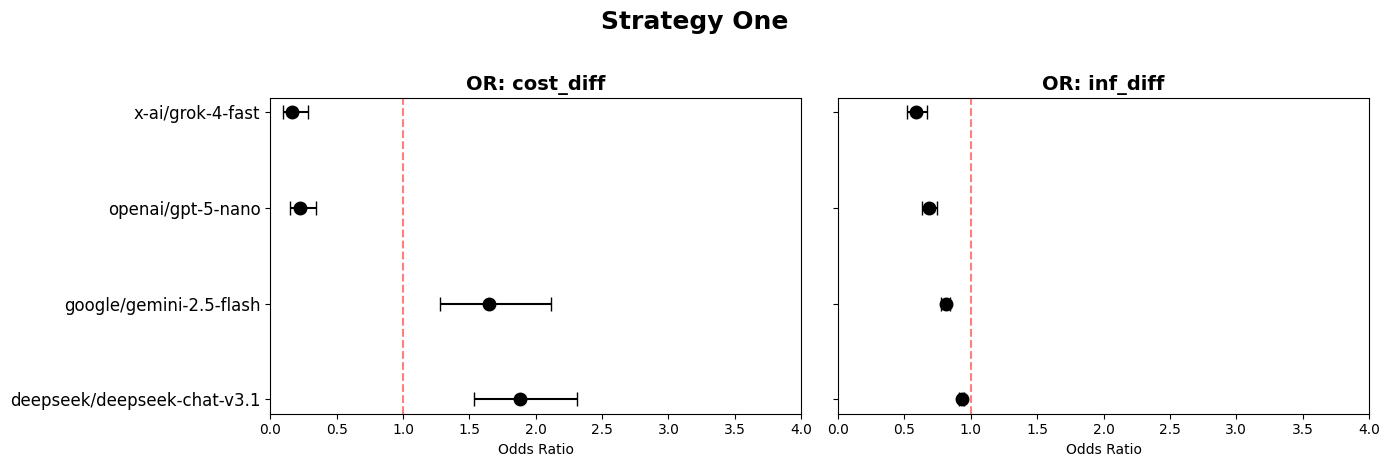

In [67]:
if 'full_results_df' in locals():
    analysis_results_one = run_dce_logit(full_results_df, strategy="strategy_one")

### Strategy Two Analysis (Political Orientation)

Prepared 4315 valid choice tasks.

OR + WTP (WITH CI) — STRATEGY: STRATEGY_TWO (INTERACTIONS)


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_capacity_context,OR_capacity_context_CI_low,OR_capacity_context_CI_high,OR_cost_x_capacity_context,OR_cost_x_capacity_context_CI_low,OR_cost_x_capacity_context_CI_high,OR_inf_x_capacity_context,OR_inf_x_capacity_context_CI_low,OR_inf_x_capacity_context_CI_high,WTP,WTP_CI_low,WTP_CI_high
0,deepseek/deepseek-chat-v3.1,1080,1.599881,1.238468,2.066764,0.929167,0.903735,0.955315,0.999861,0.994411,1.005340,1.000116,0.995554,1.004699,1.000289,0.999799,1.000779,-0.156336,-0.252367,-0.060304
1,google/gemini-2.5-flash,1075,1.749949,1.238979,2.471651,0.811243,0.766446,0.858659,1.003694,0.994921,1.012543,1.001750,0.995454,1.008085,0.999944,0.998912,1.000976,-0.373824,-0.591515,-0.156134
2,openai/gpt-5-nano,1080,0.063726,0.028225,0.143876,0.520258,0.438752,0.616907,1.000121,0.988404,1.011978,1.019375,1.006876,1.032030,1.003786,1.001226,1.006352,0.237337,0.194035,0.280640
3,x-ai/grok-4-fast,1080,0.153390,0.067291,0.349652,0.545348,0.437455,0.679853,1.004132,0.988775,1.019727,0.997042,0.981829,1.012492,0.998802,0.994620,1.003002,0.323415,0.212721,0.434109


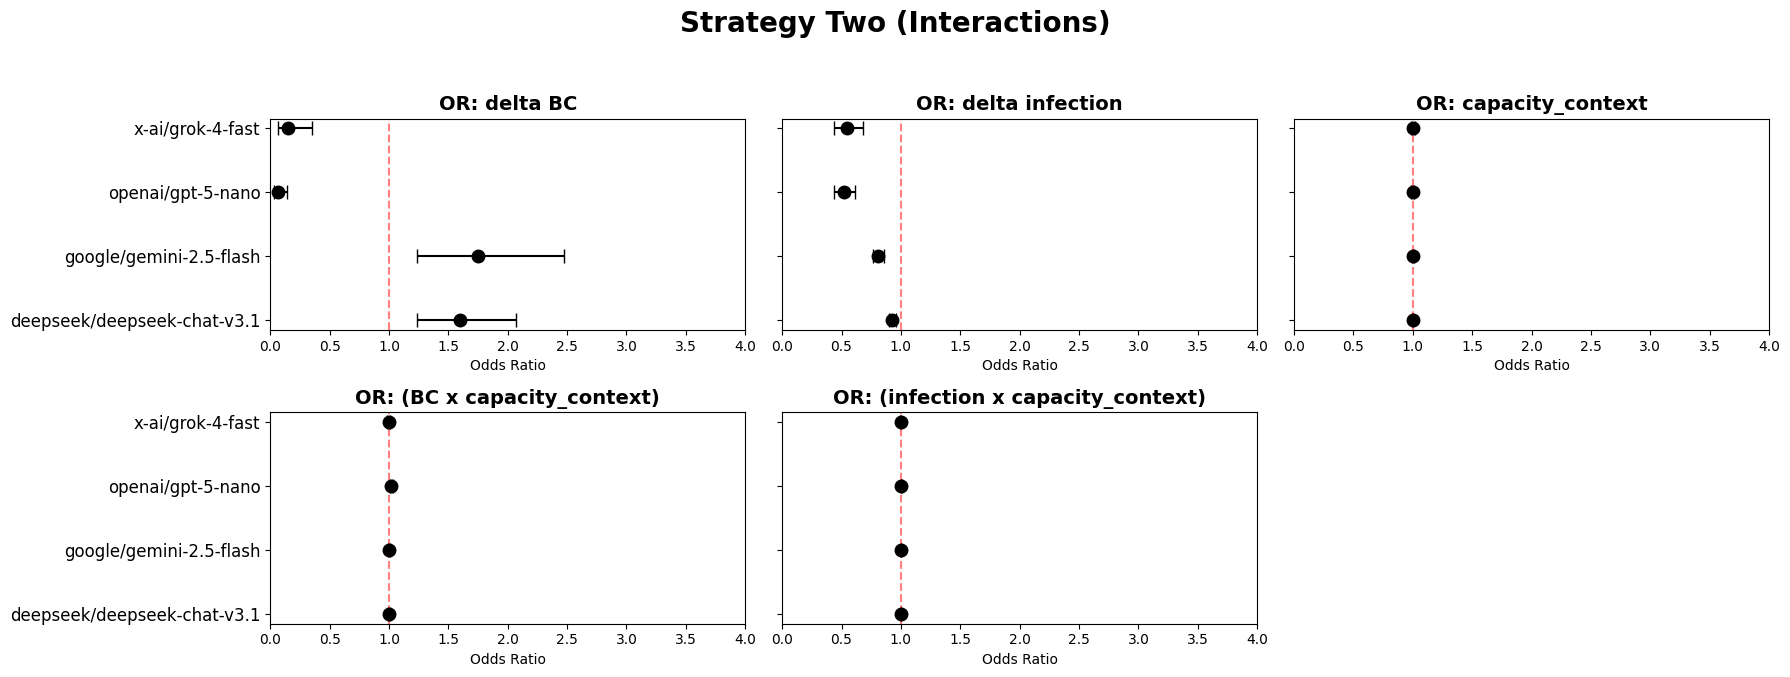

In [68]:
if 'full_results_df' in locals():
    analysis_results_two = run_dce_logit_interactions_custom(full_results_df, strategy="strategy_two", context_col="capacity_context")

#### Main Effects Only Regression

Prepared 4315 valid choice tasks for strategy_two (Main Effects Only).


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_capacity_context,OR_capacity_context_CI_low,OR_capacity_context_CI_high
0,deepseek/deepseek-chat-v3.1,1080,1.608417,1.438160,1.798831,0.942821,0.931601,0.954177,1.000227,0.994853,1.005630
1,google/gemini-2.5-flash,1075,1.907821,1.634900,2.226302,0.809065,0.788836,0.829813,1.003211,0.995913,1.010563
2,openai/gpt-5-nano,1080,0.189852,0.144051,0.250216,0.646239,0.610442,0.684136,1.003816,0.992777,1.014978
3,x-ai/grok-4-fast,1080,0.132908,0.091308,0.193462,0.514730,0.464744,0.570092,1.003628,0.988440,1.019050


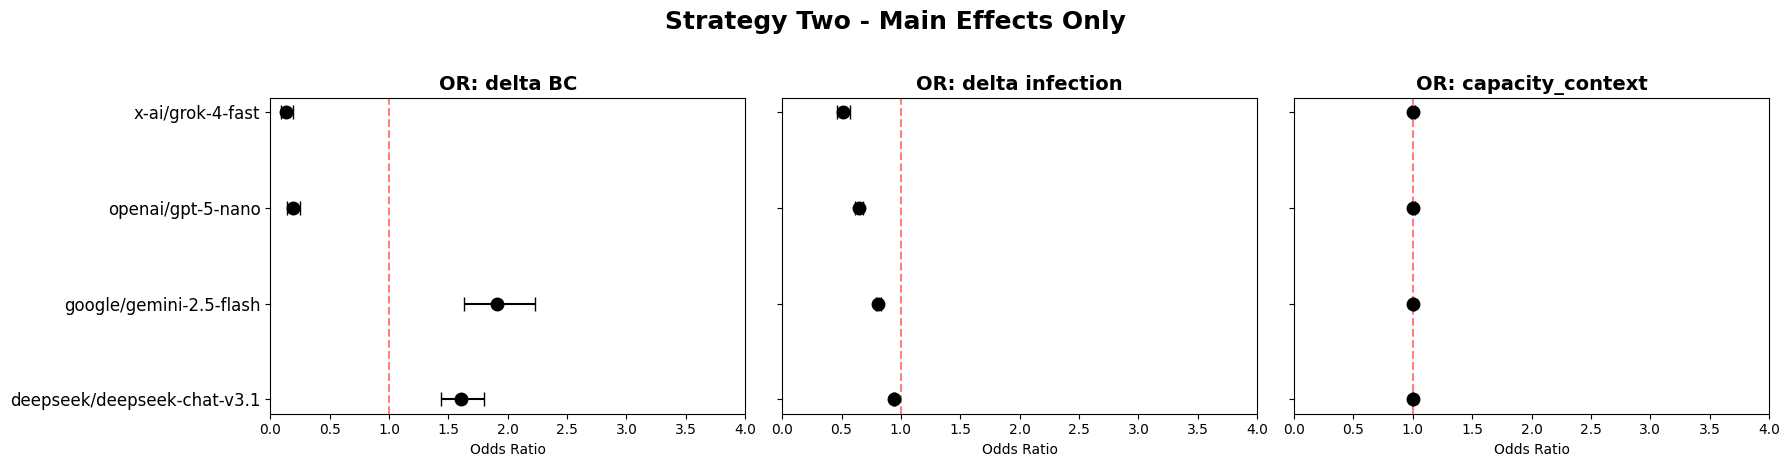

In [69]:
if 'full_results_df' in locals():
    analysis_results_two_main = run_dce_logit_with_context(full_results_df, strategy="strategy_two", context_col="capacity_context")

### Strategy Three Analysis (Economic Context)

Prepared 4316 valid choice tasks.

OR + WTP (WITH CI) — STRATEGY: STRATEGY_THREE (INTERACTIONS)


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_economic_context,OR_economic_context_CI_low,OR_economic_context_CI_high,OR_cost_x_economic_context,OR_cost_x_economic_context_CI_low,OR_cost_x_economic_context_CI_high,OR_inf_x_economic_context,OR_inf_x_economic_context_CI_low,OR_inf_x_economic_context_CI_high,WTP,WTP_CI_low,WTP_CI_high
0,deepseek/deepseek-chat-v3.1,1080,1.508750,1.187642,1.916677,0.952955,0.929272,0.977241,0.995416,0.987043,1.003861,1.002232,0.995241,1.009273,1.000079,0.999348,1.000810,-0.117166,-0.203806,-0.030525
1,google/gemini-2.5-flash,1076,1.329222,0.957770,1.844735,0.757272,0.706289,0.811935,0.995342,0.981492,1.009386,1.000949,0.991368,1.010622,0.999732,0.997665,1.001803,-0.976947,-2.080123,0.126230
2,openai/gpt-5-nano,1080,0.115461,0.054052,0.246637,0.545839,0.459640,0.648205,0.991456,0.971957,1.011346,1.005399,0.984339,1.026909,1.001907,0.997192,1.006645,0.280445,0.215692,0.345197
3,x-ai/grok-4-fast,1080,0.411757,0.261767,0.647690,0.729575,0.658525,0.808291,1.006007,0.988966,1.023341,0.983797,0.968593,0.999239,0.995154,0.991407,0.998916,0.355331,0.197513,0.513149


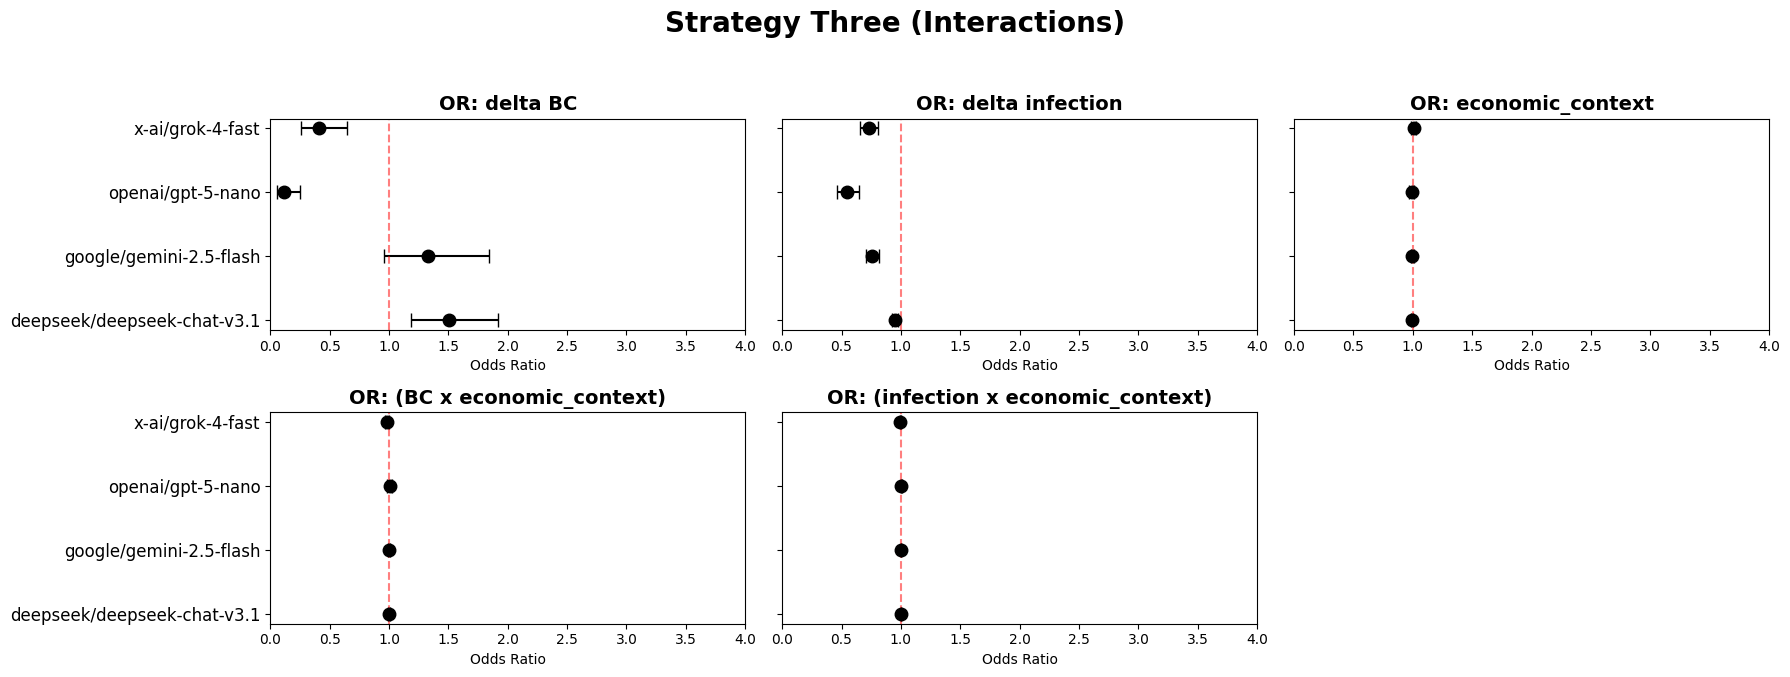

In [70]:
if 'full_results_df' in locals():
    analysis_results_three = run_dce_logit_interactions_custom(full_results_df, strategy="strategy_three", context_col="economic_context")

#### Main Effects Only Regression

Prepared 4316 valid choice tasks for strategy_three (Main Effects Only).


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_economic_context,OR_economic_context_CI_low,OR_economic_context_CI_high
0,deepseek/deepseek-chat-v3.1,1080,1.613922,1.439711,1.809213,0.955247,0.943926,0.966703,0.995109,0.986973,1.003312
1,google/gemini-2.5-flash,1076,1.367596,1.168810,1.600190,0.751252,0.726285,0.777077,0.994427,0.982291,1.006712
2,openai/gpt-5-nano,1080,0.136763,0.096939,0.192949,0.579463,0.536770,0.625551,0.991980,0.972608,1.011739
3,x-ai/grok-4-fast,1080,0.267540,0.209883,0.341037,0.642813,0.606662,0.681118,1.002783,0.986528,1.019305


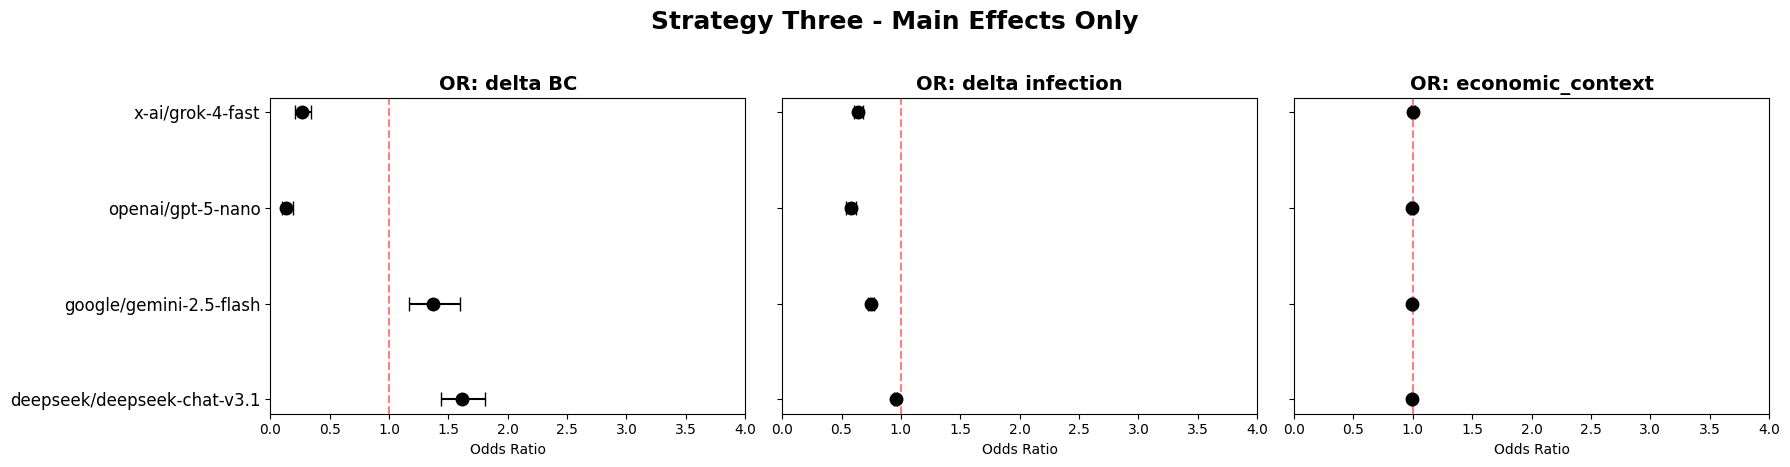

In [71]:
if 'full_results_df' in locals():
    analysis_results_three_main = run_dce_logit_with_context(full_results_df, strategy="strategy_three", context_col="economic_context")

### Strategy Four Analysis (User Preference)

Prepared 2880 valid choice tasks.

OR + WTP (WITH CI) — STRATEGY: STRATEGY_FOUR (INTERACTIONS)


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_user_preference_type_numeric,OR_user_preference_type_numeric_CI_low,OR_user_preference_type_numeric_CI_high,OR_cost_x_user_preference_type_numeric,OR_cost_x_user_preference_type_numeric_CI_low,OR_cost_x_user_preference_type_numeric_CI_high,OR_inf_x_user_preference_type_numeric,OR_inf_x_user_preference_type_numeric_CI_low,OR_inf_x_user_preference_type_numeric_CI_high,WTP,WTP_CI_low,WTP_CI_high
0,deepseek/deepseek-chat-v3.1,720,2.071461,1.583361,2.710026,0.795688,0.760742,0.832240,1.044898,0.694437,1.572227,0.154421,0.107131,0.222585,1.250538,1.190124,1.314019,-0.313829,-0.422652,-0.205006
1,google/gemini-2.5-flash,720,2.651531,1.823728,3.855080,0.693092,0.636041,0.755260,0.343930,0.178983,0.660888,0.279910,0.182211,0.429992,1.275629,1.165595,1.396050,-0.375939,-0.492088,-0.259790
2,openai/gpt-5-nano,720,0.070996,0.029534,0.170663,0.481439,0.391636,0.591833,1.022079,0.413404,2.526937,2.116174,0.759247,5.898205,1.318161,1.045299,1.662251,0.276348,0.225433,0.327263
3,x-ai/grok-4-fast,720,0.122654,0.061800,0.243431,0.491953,0.404152,0.598827,1.114359,0.343595,3.614124,0.504034,0.149880,1.695023,0.804620,0.562376,1.151212,0.338056,0.249381,0.426732


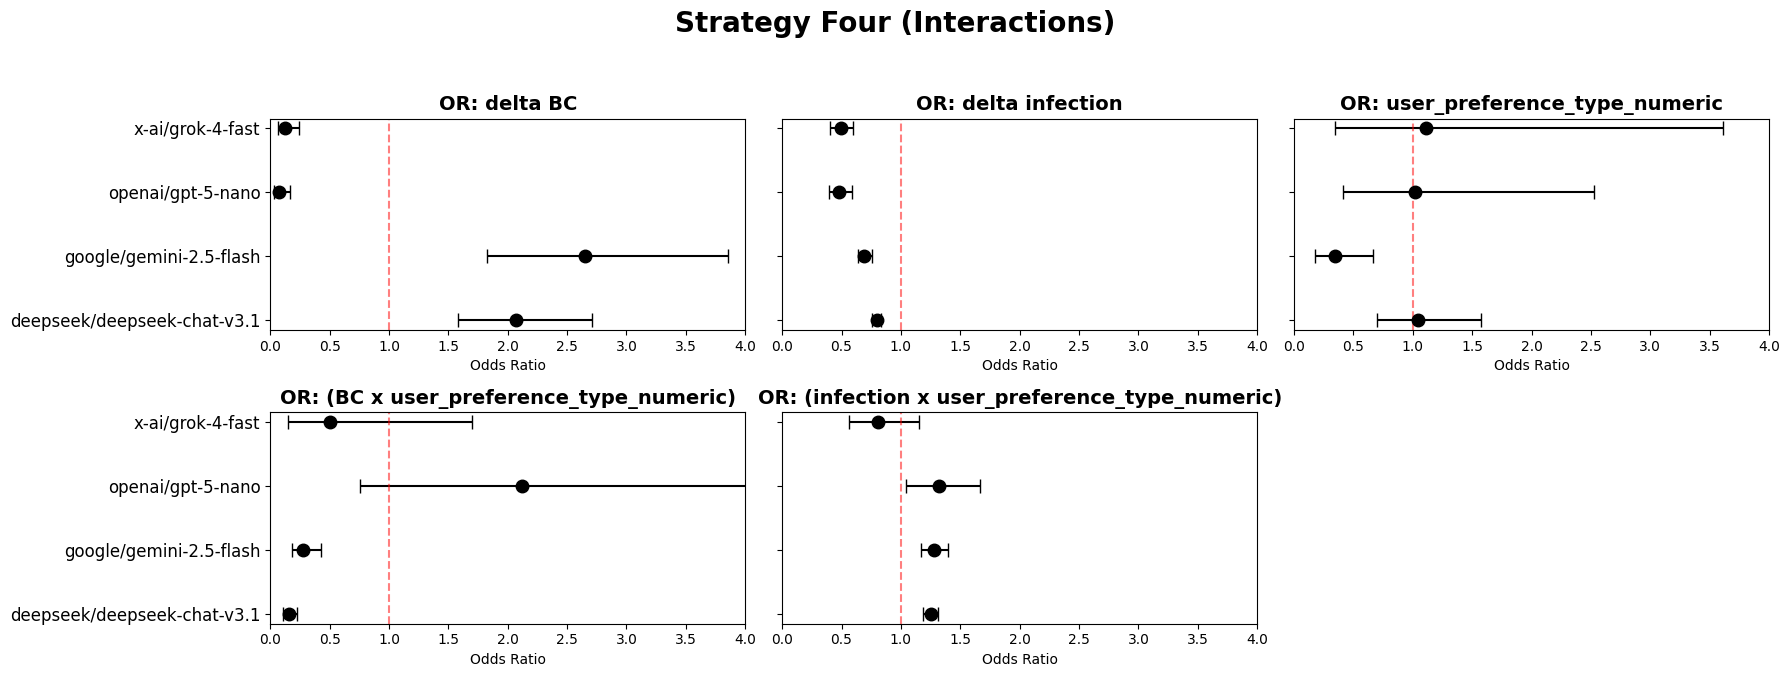

In [72]:
if 'full_results_df' in locals():
    analysis_results_four = run_dce_logit_interactions_custom(full_results_df, strategy="strategy_four", context_col="user_preference_type_numeric")

#### Main Effects Only Regression

Prepared 2880 valid choice tasks for strategy_four (Main Effects Only).


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_user_preference_type_numeric,OR_user_preference_type_numeric_CI_low,OR_user_preference_type_numeric_CI_high
0,deepseek/deepseek-chat-v3.1,720,0.739221,0.648080,0.843179,0.932260,0.918552,0.946172,1.141899,0.829641,1.571684
1,google/gemini-2.5-flash,720,1.089822,0.928957,1.278542,0.839500,0.818641,0.860890,1.064911,0.712844,1.590859
2,openai/gpt-5-nano,720,0.117708,0.075188,0.184275,0.577152,0.523854,0.635872,1.377956,0.626246,3.031977
3,x-ai/grok-4-fast,720,0.093179,0.052937,0.164013,0.451326,0.382539,0.532482,1.000000,0.333813,2.995692


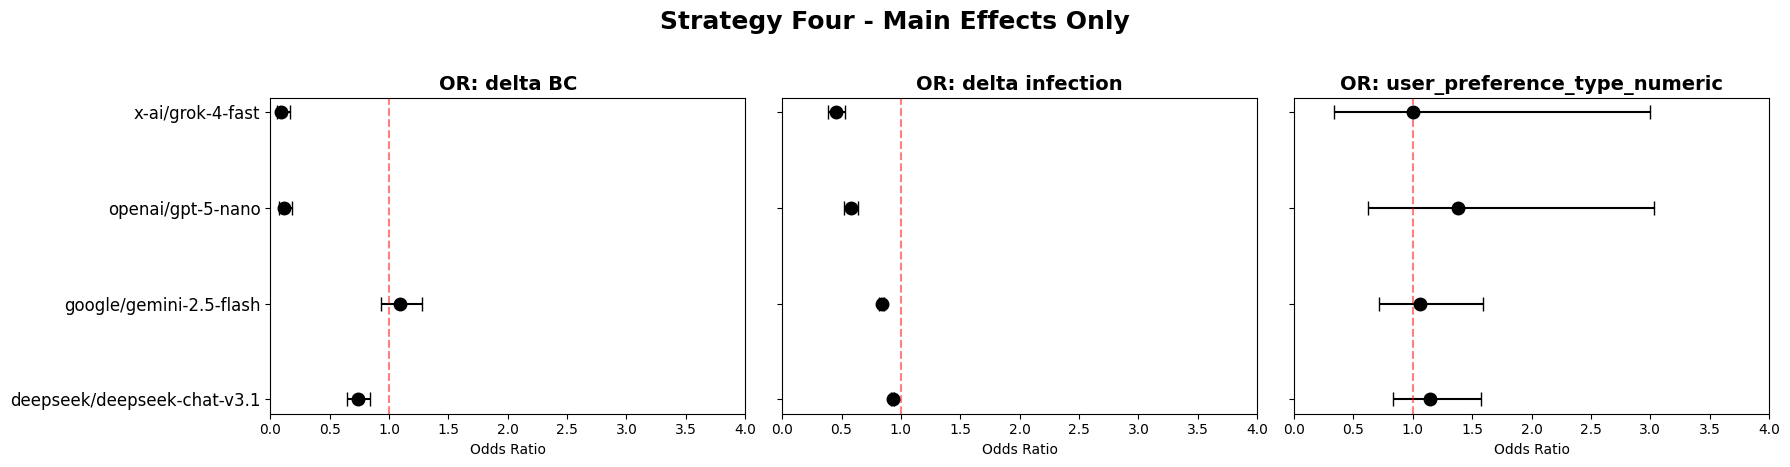

In [73]:
if 'full_results_df' in locals():
    analysis_results_four_main = run_dce_logit_with_context(full_results_df, strategy="strategy_four", context_col="user_preference_type_numeric")